In [1]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
import itur

sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.retrieval.kappa_liquid import kappa_liquid, kappa_field
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu
from radar_lwc.retrieval.gas_attenuation import specific_gas_attenuation, alpha_field
from radar_lwc.retrieval.average_ze_time import avg_ze_time

In [2]:
Processed_Dataset = "20261001_pallas_interpolation"

In [3]:
in_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
ds = xr.open_dataset(in_path)
ds_alpha = xr.open_dataset(f"../data/processed/{Processed_Dataset}/gas_attenuation.nc")
print(ds)

<xarray.Dataset> Size: 722MB
Dimensions:     (Time: 29682, range: 434)
Coordinates:
  * Time        (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ......
  * range       (range) float64 3kB 223.6 238.5 253.4 ... 1.094e+04 1.097e+04
Data variables:
    MeanVel_W   (Time, range) float64 103MB ...
    MeanVel_Ka  (Time, range) float64 103MB ...
    Ze_W        (Time, range) float64 103MB ...
    Ze_Ka       (Time, range) float64 103MB ...
    T_cloud     (Time, range) float64 103MB ...
    AH_cloud    (Time, range) float64 103MB ...
    P_cloud     (Time, range) float64 103MB ...
    LWP         (Time) float32 119kB ...
Attributes:
    description:     Ka and W on a common time/range grid + T, AH, P for the ...
    date:            20261001
    site:            Pallasjarvi
    range_matching:  interpolation
    source:          Cloudnet radar files (Ka, W); T/AH/P from RPG-Radiometer...
    Ze_units:        dBZ
    P_units:         hPa
    MeanVel_units:   m/s
    LWP_units:   

In [4]:
r = ds["range"].values
print("gate spacings present:", np.unique(np.round(np.diff(r), 1)))
# expect [22.4, 27.0, 37.7] plus the two chirp-boundary jumps

gate spacings present: [ 9.  13.5 14.9 34.1 35.2]


===============================

KAPPA AND ALPHA CALCULATION AND PLACEHOLDERS FOR NOW

====================================

In [5]:
ds["alpha_W"] = ds_alpha["alpha_W"]
ds["alpha_Ka"] = ds_alpha["alpha_Ka"]

In [6]:
alpha_W = ds["alpha_W"]
alpha_Ka = ds["alpha_Ka"]

In [7]:
print(alpha_W)
print(alpha_Ka)

print(f"W-band:  {float(alpha_W.min()):.3f} - {float(alpha_W.max()):.3f} dB/km")
print(f"Ka-band: {float(alpha_Ka.min()):.3f} - {float(alpha_Ka.max()):.3f} dB/km")

<xarray.DataArray 'alpha_W' (Time: 29682, range: 434)> Size: 103MB
[12881988 values with dtype=float64]
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 3kB 223.6 238.5 253.4 ... 1.094e+04 1.097e+04
Attributes:
    units:      dB km-1
    long_name:  Gaseous attenuation at 94.0 GHz
    model:      ITU-R P.676
<xarray.DataArray 'alpha_Ka' (Time: 29682, range: 434)> Size: 103MB
[12881988 values with dtype=float64]
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 3kB 223.6 238.5 253.4 ... 1.094e+04 1.097e+04
Attributes:
    units:      dB km-1
    long_name:  Gaseous attenuation at 35.0 GHz
    model:      ITU-R P.676
W-band:  0.007 - 0.443 dB/km
Ka-band: 0.005 - 0.106 dB/km


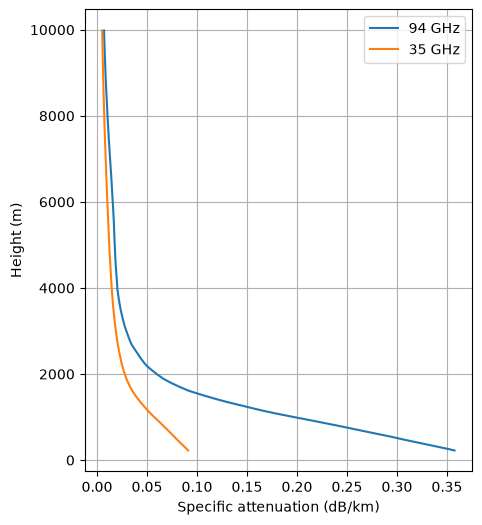

In [8]:
import matplotlib.pyplot as plt

t = 0

plt.figure(figsize=(5, 6))

plt.plot(alpha_W.isel(Time=t), alpha_W["range"], label="94 GHz")
plt.plot(alpha_Ka.isel(Time=t), alpha_Ka["range"], label="35 GHz")

plt.xlabel("Specific attenuation (dB/km)")
plt.ylabel("Height (m)")
plt.legend()
plt.grid()

plt.show()

In [9]:
# W-band (94 GHz)
kappa_W = kappa_field(
    T_field=ds["T_cloud"],
    freq_ghz=94.0,
)

# Ka-band (35 GHz)
kappa_Ka = kappa_field(
    T_field=ds["T_cloud"],
    freq_ghz=35.0,
)

C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\dielectric.py:51: RuntimeWarning: invalid value encountered in divide
  eps = (eps0 - eps1) / (1.0 + 1j * (freq_ghz / f_p)) \
C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\dielectric.py:52: RuntimeWarning: invalid value encountered in divide
  + (eps1 - eps2) / (1.0 + 1j * (freq_ghz / f_s)) \
C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\kappa_liquid.py:29: RuntimeWarning: invalid value encountered in divide
  K     = (eps - 1.0) / (eps + 2.0)            # dielectric factor (note +2, not +1!)


In [10]:
kappa = kappa_liquid (94.0, 283)
print(kappa)

4.296428658606702


In [11]:
print(kappa_W)
print(kappa_Ka)

print(f"W-band:  {float(kappa_W.min()):.3f} - {float(kappa_W.max()):.3f} dB km⁻¹ (g m⁻³)⁻¹")
print(f"Ka-band: {float(kappa_Ka.min()):.3f} - {float(kappa_Ka.max()):.3f} dB km⁻¹ (g m⁻³)⁻¹")

<xarray.DataArray 'kappa_94GHz' (Time: 29682, range: 434)> Size: 103MB
array([[4.55782312, 4.54903517, 4.54002897, ...,        nan,        nan,
               nan],
       [4.55780971, 4.54902265, 4.54001733, ...,        nan,        nan,
               nan],
       [4.55779637, 4.54901019, 4.54000574, ...,        nan,        nan,
               nan],
       ...,
       [4.61771715, 4.61228964, 4.60623101, ...,        nan,        nan,
               nan],
       [4.61771715, 4.61228964, 4.60623101, ...,        nan,        nan,
               nan],
       [4.61771715, 4.61228964, 4.60623101, ...,        nan,        nan,
               nan]], shape=(29682, 434))
Coordinates:
  * Time     (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ... 20...
  * range    (range) float64 3kB 223.6 238.5 253.4 ... 1.094e+04 1.097e+04
Attributes:
    units:      dB km-1 (g m-3)-1
    long_name:  Rayleigh attenuation coefficient at 94.0 GHz
    model:      Liebe et al. 1989 double-Debye
<xarray.D

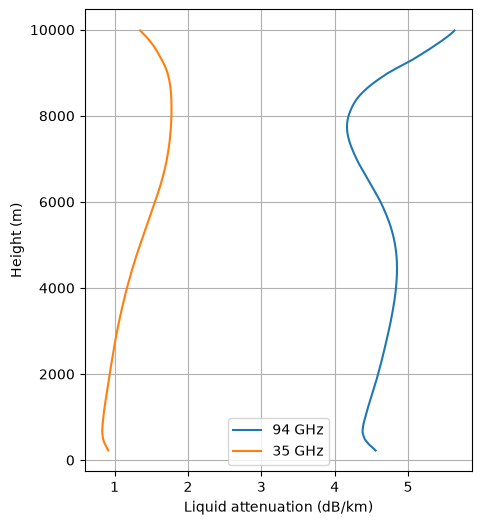

In [12]:
import matplotlib.pyplot as plt

t = 0

plt.figure(figsize=(5, 6))

plt.plot(kappa_W.isel(Time=t), kappa_W["range"], label="94 GHz")
plt.plot(kappa_Ka.isel(Time=t), kappa_Ka["range"], label="35 GHz")

plt.xlabel("Liquid attenuation (dB/km)")
plt.ylabel("Height (m)")
plt.legend()
plt.grid()

plt.show()

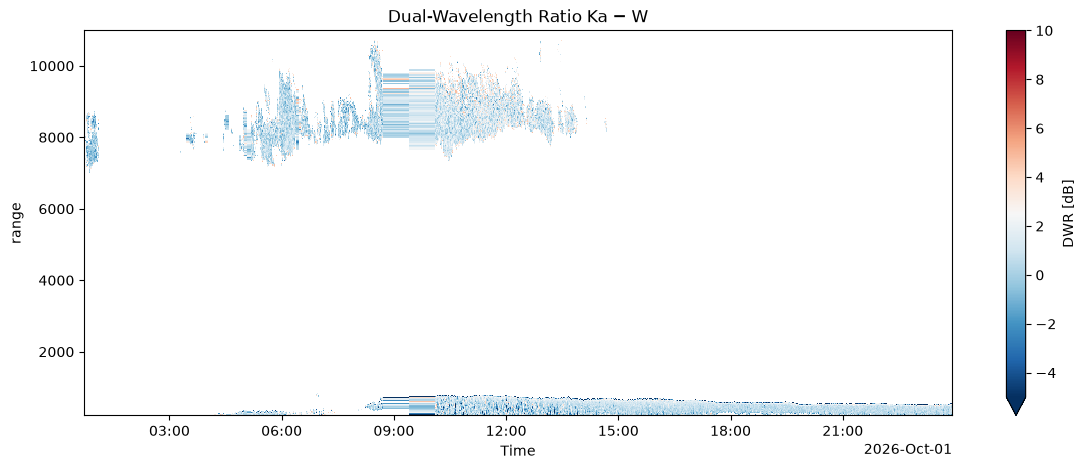

In [13]:
dwr = ds["Ze_Ka"]- ds["Ze_W"]      # in dB
dwr.name = "DWR"
dwr.attrs["units"] = "dB"
dwr = dwr.where(dwr <= 5)
fig, ax = plt.subplots(figsize=(14, 5))
dwr.plot(x="Time", y="range", cmap="RdBu_r", vmin=-5, vmax=10, ax=ax, cbar_kwargs={"label": "DWR [dB]"})
ax.set_title("Dual-Wavelength Ratio Ka − W")
plt.show()

In [14]:
alpha_w = xr.DataArray(
    np.full_like(dwr.values, 0.65),
    dims=dwr.dims,
    coords=dwr.coords,
    name="alpha_W",
)

alpha_ka = xr.DataArray(
    np.full_like(dwr.values, 0.14),
    dims=dwr.dims,
    coords=dwr.coords,
    name="alpha_Ka",
)

In [15]:
kappa_w = xr.DataArray(
    np.full_like(dwr.values, 4.29),
    dims=dwr.dims,
    coords=dwr.coords,
    name="kappa_W",
)

kappa_ka = xr.DataArray(
    np.full_like(dwr.values, 0.80),
    dims=dwr.dims,
    coords=dwr.coords,
    name="kappa_Ka",
)

=================================================

DWR

=================================================

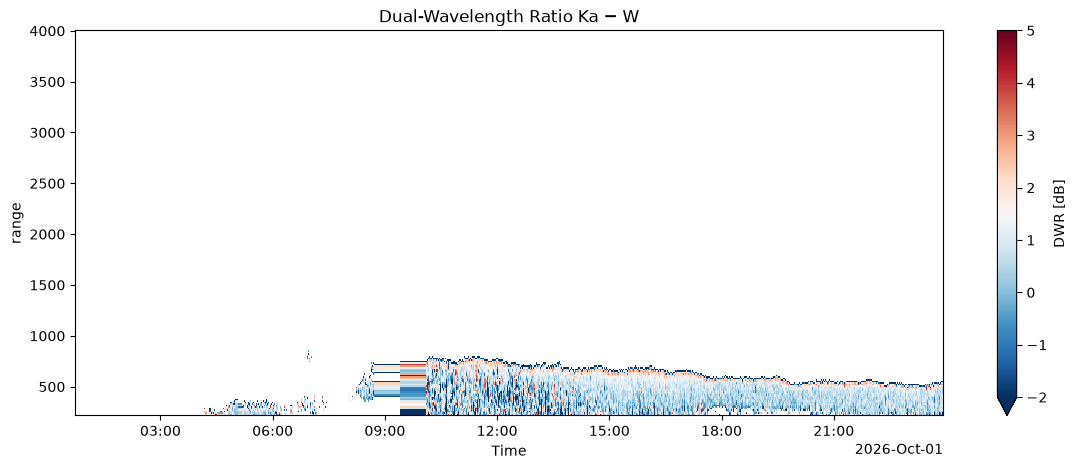

In [16]:
dwr_2km = dwr.sel(range=slice(0, 4000))

fig, ax = plt.subplots(figsize=(14, 5))

dwr_2km.plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    vmin=-2,
    vmax=5,
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio Ka − W")
plt.show()

In [17]:
# %% Check frequency of >1 dB gate-to-gate DWR jumps

dwr_2km_diff = np.abs(dwr_2km.diff(dim="range"))

fraction = float((dwr_2km_diff > 1.0).mean())

print(f"Fraction of gate-to-gate DWR jumps > 1 dB: {fraction:.2%}")

Fraction of gate-to-gate DWR jumps > 1 dB: 1.54%


In [18]:
# 1. Confirm DWR is in dB
print("DWR stats (cloud only):")
cloud_dwr = dwr.where(dwr > -5).where(dwr < 20)  # rough cloud filter
print(f"  median: {float(cloud_dwr.median()):.2f}")
print(f"  90th pct: {float(cloud_dwr.quantile(0.9)):.2f}")       # 90% of DWR are below 4.49dB
print(f"  range: {float(cloud_dwr.min()):.2f} to {float(cloud_dwr.max()):.2f}")

# 2. Confirm range axis
print(f"\nRange axis: first={float(dwr['range'][0]):.1f} m, last={float(dwr['range'][-1]):.1f} m")
print(f"Δh = {float(dwr['range'][1] - dwr['range'][0]):.1f} m")

# 3. Check kappa
print(f"\nkappa_W: {float(kappa_w.mean()):.3f} dB/km/(g/m³)")
print(f"kappa_Ka: {float(kappa_ka.mean()):.3f} dB/km/(g/m³)")
print(f"Δκ: {float((kappa_w - kappa_ka).mean()):.3f}")


DWR stats (cloud only):
  median: 0.80
  90th pct: 2.33
  range: -5.00 to 5.00

Range axis: first=223.6 m, last=10970.7 m
Δh = 14.9 m

kappa_W: 4.290 dB/km/(g/m³)
kappa_Ka: 0.800 dB/km/(g/m³)
Δκ: 3.490


====================================

CLOUD MASK

====================================

In [19]:


cloud_mask = (
    ds["Ze_Ka"].notnull()
    & ds["Ze_W"].notnull()
    & (ds["Ze_Ka"] > -41)  #constant Threshold
    & (ds["Ze_W"] > -41)
)
cloud_mask.name = "cloud_mask"
print(f"Cloud fraction (full column): {float(cloud_mask.mean()):.2%}")     # .2: two digits after decimal and %: that in percentage; .mean of Boolean array takes true as 1 and false as 0. So True divided by all Booleans in Array 

# 2 km version to match your existing workflow
cloud_mask_2km = cloud_mask.sel(range=slice(0, 4000))                  #.sel(range=slice(0, 4000)) only takes first 2 km
print(f"Cloud fraction (0–2 km):     {float(cloud_mask_2km.mean()):.2%}")


Cloud fraction (full column): 7.72%
Cloud fraction (0–2 km):     8.78%


In [20]:
dZ_dh = ds["Ze_W"].differentiate("range") * 100   # dB per 100 m
dZ_dh = dZ_dh.where(cloud_mask)
print(np.nanpercentile(dZ_dh, [5, 25, 50, 75, 95]))

[-10.05418693  -2.02401642   0.65976459   3.29815373   8.63484556]


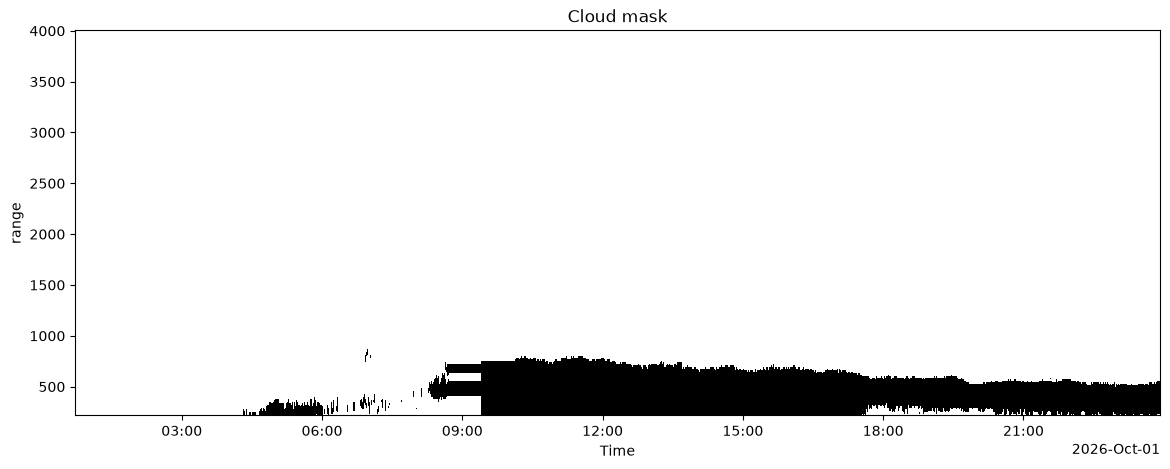

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

cloud_mask.sel(range=slice(0, 4000)).plot(
    x="Time",
    y="range",
    cmap="Greys",
    add_colorbar=False,
    ax=ax,
)

ax.set_title("Cloud mask")
plt.show()

BOXFILTER

In [22]:
# %% 5x5 neighbour filter (Zhu 2019): >=13 significant returns in 5(time)x5(range) box
from scipy.ndimage import uniform_filter

min_neighbours = 13
box = (5, 5)  # (Time, range) — adjust order if your dims are (range, Time)

def neighbour_filter(significant):
    """significant: boolean DataArray (Time, range) of valid/above-noise returns."""
    window_size = box[0] * box[1]
    count = (
    uniform_filter(                     # uniform filter checks if significant (the reflectivity assumptions) is True in a 5x5 box around each gate, and counts how many are True. The multiplication by (box[0] * box[1])(5 * 5) scales the result to the number of gates in the box.
        significant.astype(float),
        size=box,
        mode="reflect"      # Mirror the data at the edge
    )
    * window_size
)                     
    return xr.DataArray(count >= min_neighbours, dims=significant.dims, coords=significant.coords)          # returns dataarray where True means enough adjacent cells are fulfilling the criteria (i.e. are True). False means not enough adjacent cells are fulfilling the criteria (i.e. are False).

sig_W  = ds["Ze_W"].notnull()  & (ds["Ze_W"]  > -41)                        #Same as cloud mask before
sig_Ka = ds["Ze_Ka"].notnull() & (ds["Ze_Ka"] > -41)                        #Same as cloud mask before

neighbour_mask_W  = neighbour_filter(sig_W)
neighbour_mask_Ka = neighbour_filter(sig_Ka)

Ze_W_filt  = ds["Ze_W"].where(sig_W  & neighbour_mask_W)                  # Both the Value itself and enough neighbours have to be significant.
Ze_Ka_filt = ds["Ze_Ka"].where(sig_Ka & neighbour_mask_Ka)
print(f"Ka-band gates removed: {float((sig_Ka & ~neighbour_mask_Ka).sum())}")

common_mask = (
    sig_W & neighbour_mask_W &
    sig_Ka & neighbour_mask_Ka
)                                      # Both Masks together

Ka-band gates removed: 33175.0


In [23]:
ze_ka_avg = avg_ze_time(ds["Ze_Ka"].sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds["Ze_W"].sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"

In [24]:
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d, dwr_2km_smoothed,
    input_core_dims=[["range"]], output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold}, vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")


Gates replaced by interpolation: 7210 (0.11% of all gates)


criterion              kept   sigma_DWR  implied dLWC
const -50 dBZ          7.64%      1.086 dB       0.920
const -49 dBZ          7.64%      1.085 dB       0.920
const -48 dBZ          7.64%      1.085 dB       0.919
const -47 dBZ          7.64%      1.084 dB       0.919
const -46 dBZ          7.63%      1.083 dB       0.918
const -45 dBZ          7.63%      1.083 dB       0.918
const -44 dBZ          7.62%      1.081 dB       0.916
const -43 dBZ          7.60%      1.072 dB       0.909
const -42 dBZ          7.57%      1.056 dB       0.895
const -41 dBZ          7.53%      1.037 dB       0.879
const -40 dBZ          7.50%      1.015 dB       0.860
const -39 dBZ          7.45%      0.992 dB       0.841
const -38 dBZ          7.40%      0.969 dB       0.822
const -37 dBZ          7.35%      0.950 dB       0.805
const -36 dBZ          7.28%      0.931 dB       0.789
const -35 dBZ          7.21%      0.914 dB       0.775
const -34 dBZ          7.12%      0.900 dB       0.762
const -33 d

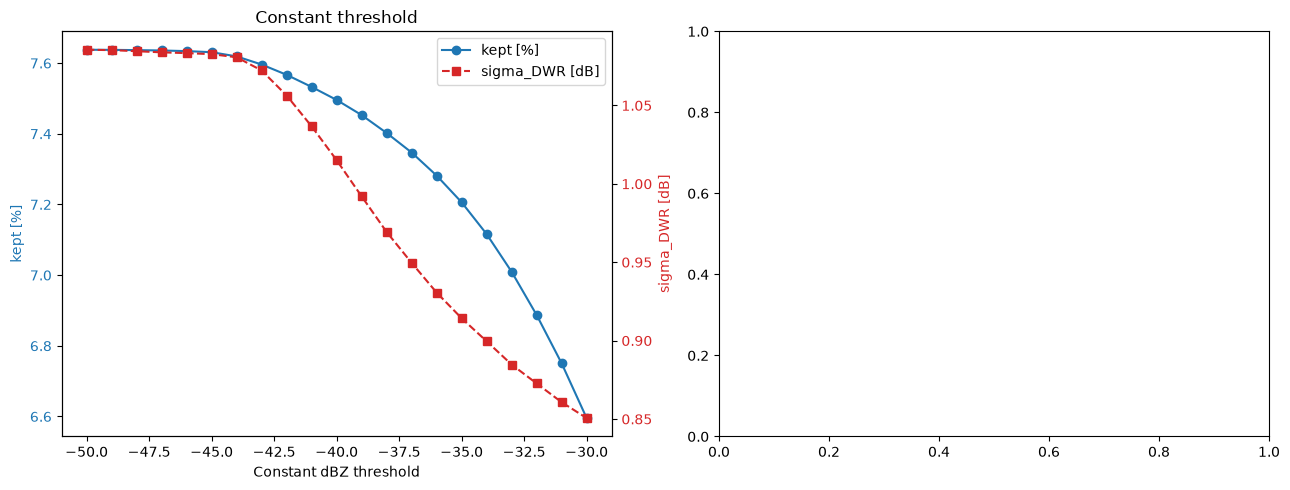

In [25]:
# %% Constant dBZ threshold vs sensitivity-limit-based, side by side
thresholds = np.arange(-50, -29, 1)    # -50 to -30 dBZ, 1 dB steps
      # SL + 0 to SL + 15 dB, 1 dB steps

def dwr_stats(m):
    m = m & neighbour_filter(m)
    D = (ds["Ze_Ka"] - ds["Ze_W"]).where(m).values
    d = D[:, 1:] - D[:, :-1]
    d = d[np.isfinite(d)]
    sig = np.std(d) / np.sqrt(2) if d.size else np.nan
    dlwc = sig / (2 * 3.4 * 0.0224 * np.sqrt(9 * 80 / 12))
    return float(m.mean()), sig, dlwc

results_const, results_sl = [], []

for thr in thresholds:
    m = (ds["Ze_W"].notnull() & ds["Ze_Ka"].notnull()
         & (ds["Ze_W"] > thr) & (ds["Ze_Ka"] > thr))
    kept, sig, dlwc = dwr_stats(m)
    results_const.append((thr, kept, sig, dlwc))



results_const = np.array(results_const)   # cols: thr, kept, sigma, dlwc
     # cols: marg, kept, sigma, dlwc

# Optional: still print the table if you want it alongside the plot
print(f"{'criterion':<18}{'kept':>9}{'sigma_DWR':>12}{'implied dLWC':>14}")
for thr, kept, sig, dlwc in results_const:
    print(f"const {thr:.0f} dBZ{'':<7}{kept:>8.2%}{sig:>11.3f} dB{dlwc:>12.3f}")


# %% Plot: kept fraction & sigma_DWR vs threshold, const vs SL-based
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, res, xlabel, title in [
    (axes[0], results_const, "Constant dBZ threshold", "Constant threshold"),
    
]:
    x, kept, sig, _ = res.T
    l1, = ax.plot(x, kept * 100, "o-", color="tab:blue", label="kept [%]")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("kept [%]", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.set_title(title)

    ax2 = ax.twinx()
    l2, = ax2.plot(x, sig, "s--", color="tab:red", label="sigma_DWR [dB]")
    ax2.set_ylabel("sigma_DWR [dB]", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    ax.legend(handles=[l1, l2], loc="best")

plt.tight_layout(); plt.show()



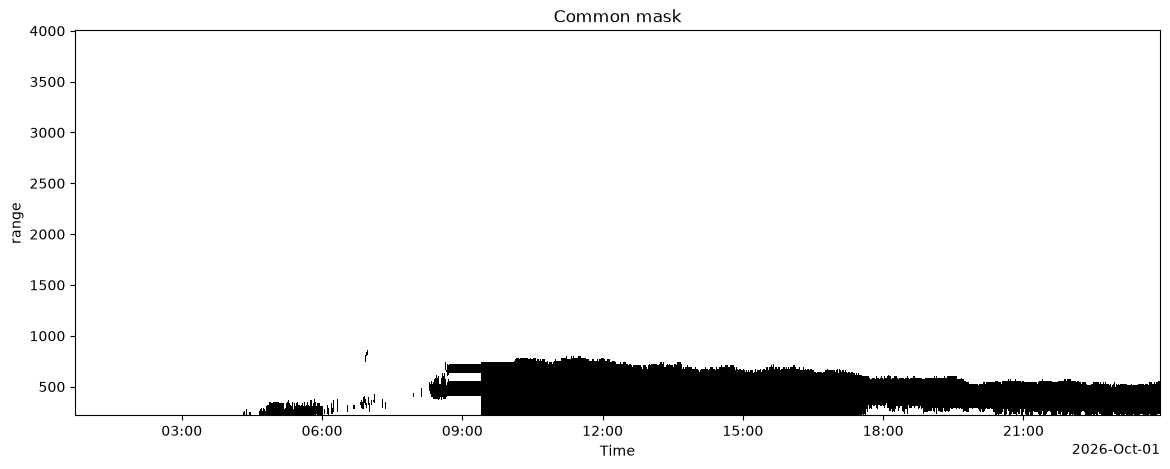

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

common_mask.sel(range=slice(0, 4000)).plot(
    x="Time",
    y="range",
    cmap="Greys",
    add_colorbar=False,
    ax=ax,
)

ax.set_title("Common mask")
plt.show()

DRIZZLE MASK

In [27]:
# %% Drizzle filter (Hogan 2005 / Zhu 2019): |v_W - v_Ka| > 0.1 m/s
dv_threshold = 0.15  # m/sAdd

dv = (ds["MeanVel_W"] - ds["MeanVel_Ka"]).where(common_mask)    # Velocity difference at cloud_masked gates; .where(cloud_mask) keeps only the values where cloud_mask is True, and sets the rest to NaN.

min_drizzle_height = 550   # m
max_drizzle_height = 4000  # m

dv = dv.where(
    (dv["range"] >= min_drizzle_height)
    & (dv["range"] <= max_drizzle_height)
)

gate_flag = np.abs(dv) > dv_threshold          # Is this gate above the drizzle threshold?
profile_flag = gate_flag.any(dim="range")       # Does this profile contain any drizzle gate? -> whole profile is true in that range. 

drizzle_mask = ~profile_flag                    # True = keep profile, False = reject profile   (Negates the profile_flag, so that True means keep and False means reject)
drizzle_mask.name = "drizzle_mask"

print(f"Profiles removed by drizzle filter: {float(profile_flag.mean()):.2%}")

Profiles removed by drizzle filter: 42.90%


In [28]:
# %% Drizzle diagnostics

max_dv = np.abs(dv).max(dim="range")

n_exceed = gate_flag.sum(dim="range")

fraction_exceed = (
    gate_flag.sum(dim="range")
    / cloud_mask.sum(dim="range")
)

print(f"Median max |Δv|: {float(max_dv.median()):.3f} m/s")
print(f"Median exceeding gates: {float(n_exceed.median()):.1f}")
print(f"Median fraction exceeding: {float(fraction_exceed.median()):.2%}")
print(n_exceed.quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

Median max |Δv|: 0.223 m/s
Median exceeding gates: 0.0
Median fraction exceeding: 0.00%
<xarray.DataArray (quantile: 5)> Size: 40B
array([0., 2., 5., 6., 9.])
Coordinates:
  * quantile  (quantile) float64 40B 0.5 0.75 0.9 0.95 0.99


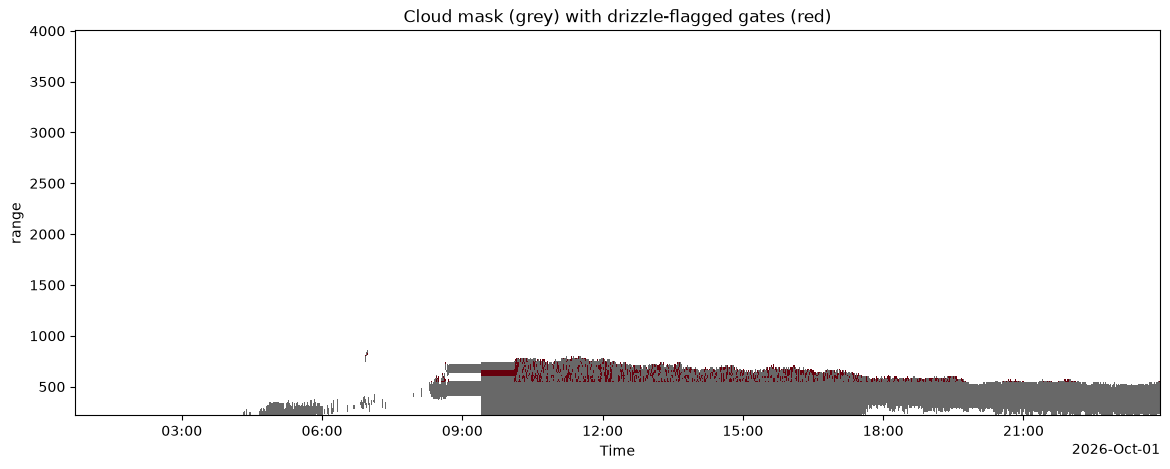

Drizzle-flagged fraction within cloud: 4.48%


In [29]:
# %% Plot common_mask + drizzle_mask together
fig, ax = plt.subplots(figsize=(14, 5))

# Background: cloud mask (grey)
common_mask.sel(range=slice(0, 4000)).plot(
    x="Time", y="range", cmap="Greys", vmin=0, vmax=1.5,
    add_colorbar=False, ax=ax,
)

# Overlay: drizzle-flagged gates (red), only where cloud is present
gate_flag_plot = gate_flag.sel(range=slice(0, 4000))
gate_flag_plot.where(gate_flag_plot).plot(
    x="Time", y="range", cmap="Reds", vmin=0, vmax=1,
    add_colorbar=False, ax=ax,
)

ax.set_title("Cloud mask (grey) with drizzle-flagged gates (red)")
plt.show()

print(f"Drizzle-flagged fraction within cloud: "
      f"{float(gate_flag.sum() / common_mask.sum()):.2%}")

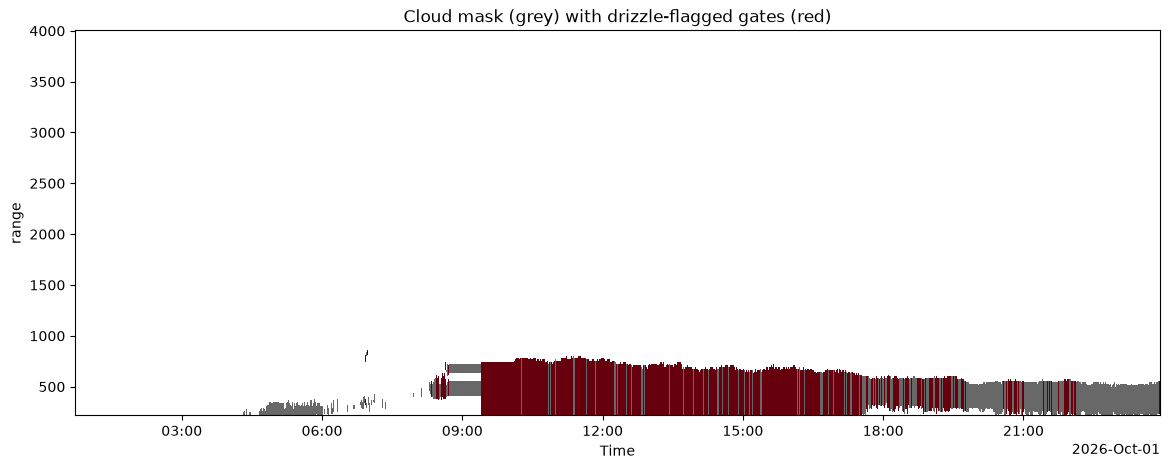

Drizzle-flagged fraction within cloud: 61.63%


In [30]:
# %% Plot common_mask + drizzle_mask together
fig, ax = plt.subplots(figsize=(14, 5))

# Background: cloud mask (grey)
common_mask.sel(range=slice(0, 4000)).plot(
    x="Time", y="range", cmap="Greys", vmin=0, vmax=1.5,
    add_colorbar=False, ax=ax,
)

# Overlay: drizzle-flagged gates (red), only where cloud is present
drizzle_flag_plot = (~drizzle_mask & common_mask).sel(range=slice(0, 4000))
drizzle_flag_plot.where(drizzle_flag_plot).plot(
    x="Time", y="range", cmap="Reds", vmin=0, vmax=1,
    add_colorbar=False, ax=ax,
)

ax.set_title("Cloud mask (grey) with drizzle-flagged gates (red)")
plt.show()

print(f"Drizzle-flagged fraction within cloud: "
      f"{float((~drizzle_mask & common_mask).sum() / common_mask.sum()):.2%}")

Text(0, 0.5, 'Profiles')

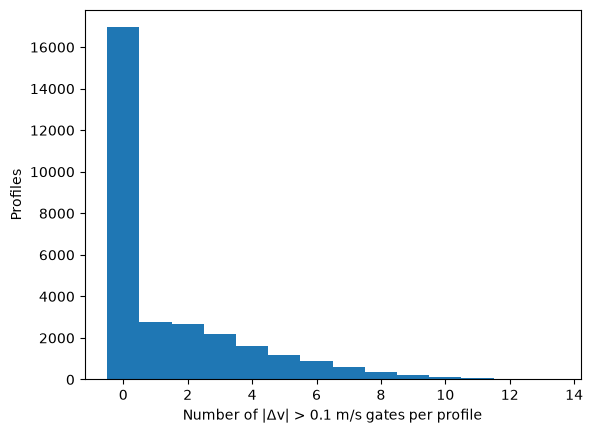

In [31]:
n_exceed = gate_flag.sum(dim="range")

plt.hist(n_exceed, bins=np.arange(0, 15) - 0.5)
plt.xlabel("Number of |Δv| > 0.1 m/s gates per profile")
plt.ylabel("Profiles")

In [32]:
# %% Diagnose the drizzle-filter kill rate
dv = (ds["MeanVel_W"] - ds["MeanVel_Ka"]).where(common_mask)
dv_vals = dv.values[np.isfinite(dv.values)]
print(f"velocity-difference: mean={dv_vals.mean():+.3f}  std={dv_vals.std():.3f} m/s")
print(f"median={np.median(dv_vals):+.3f}  |  fraction |dv|>0.1: {(np.abs(dv_vals)>0.1).mean():.1%}")
# Is the exceedance near cloud base (real drizzle) or everywhere (mismatch/noise)?

velocity-difference: mean=+0.022  std=0.149 m/s
median=+0.040  |  fraction |dv|>0.1: 33.3%


In [33]:
med = np.median(dv_vals)
mad = np.median(np.abs(dv_vals - med))
sigma_robust = 1.4826 * mad
print(f"sigma_robust (MAD) = {sigma_robust:.3f} m/s   vs std = {dv_vals.std():.3f}")
for k in [3, 4, 5]:
    thr = k * sigma_robust
    print(f"  {k}·sigma_robust = {thr:.3f} m/s -> flags {(np.abs(dv_vals)>thr).mean():.1%} of gates")
print("percentiles of |dv|:", np.percentile(np.abs(dv_vals), [90, 95, 99]).round(3))

sigma_robust (MAD) = 0.072 m/s   vs std = 0.149
  3·sigma_robust = 0.217 m/s -> flags 12.1% of gates
  4·sigma_robust = 0.289 m/s -> flags 6.4% of gates
  5·sigma_robust = 0.361 m/s -> flags 3.4% of gates
percentiles of |dv|: [0.238 0.317 0.51 ]


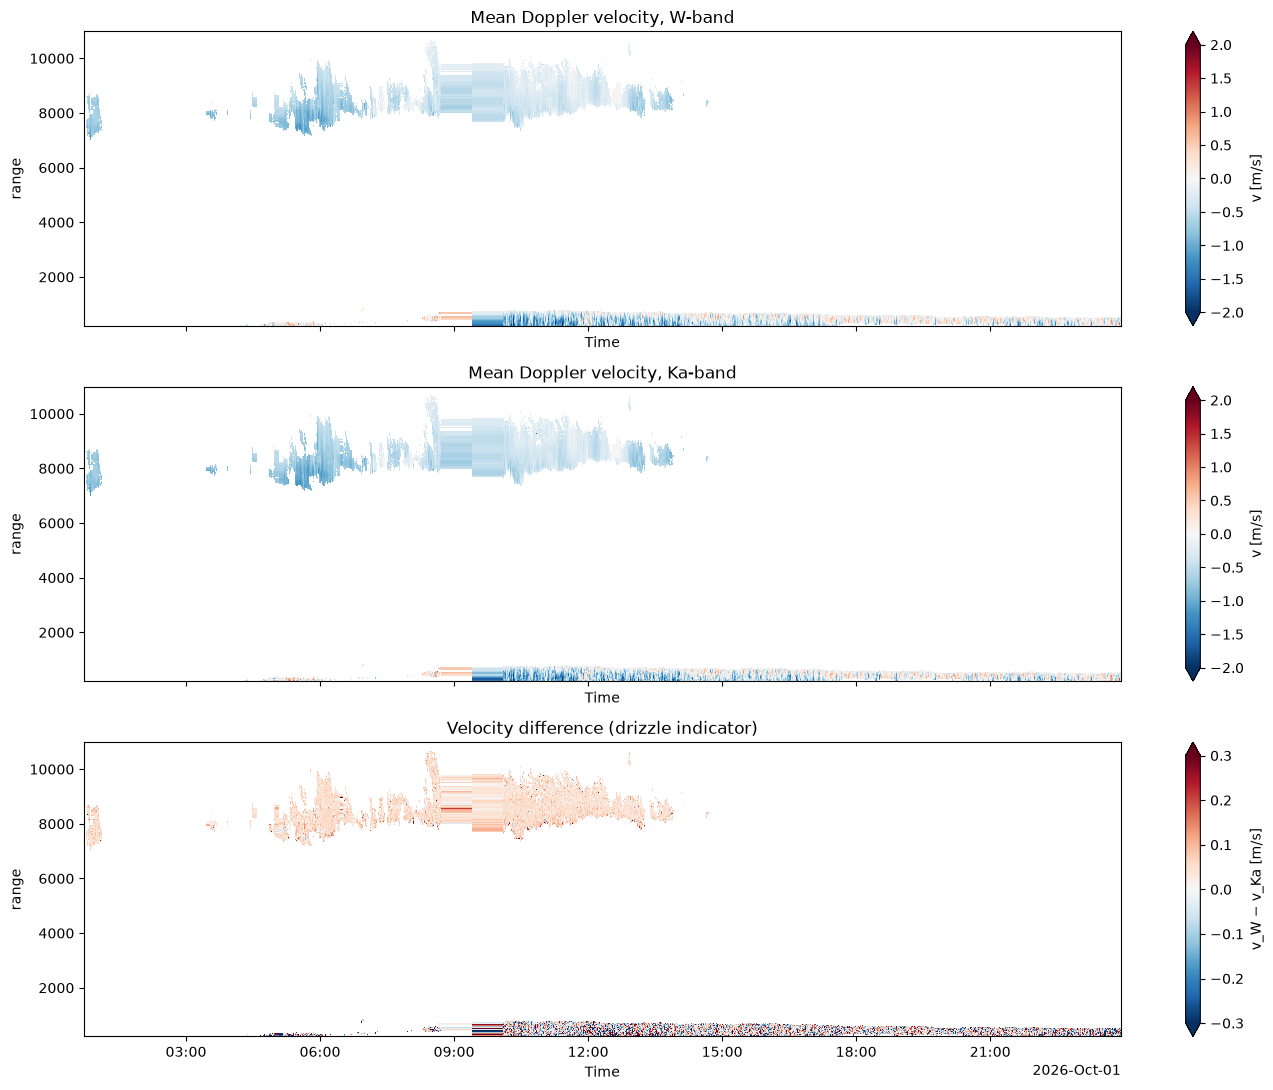

mean +0.022 | median +0.040 | std 0.149 m/s
  |dv| > 0.1: 33.32%
  |dv| > 0.15: 21.49%
  |dv| > 0.2: 13.96%
  |dv| > 0.3: 5.83%


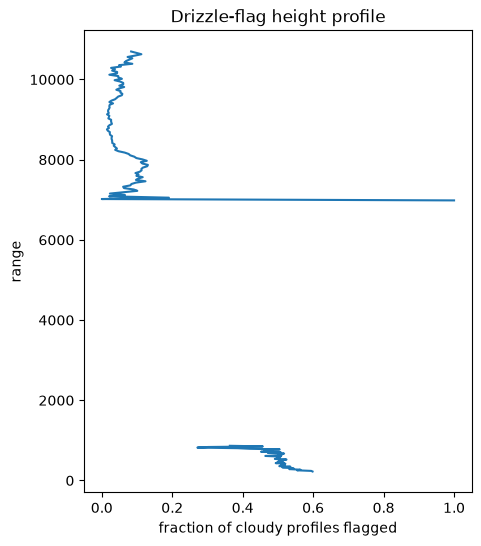


flagged runs: 119886 total | isolated (1 gate): 36.4% | >=3 gates: 38.3% | longest: 34


In [34]:
# %% Both Doppler velocities + their difference
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, sharey=True)
for ax, (fld, ttl) in zip(axes[:2], [(ds["MeanVel_W"], "W-band"), (ds["MeanVel_Ka"], "Ka-band")]):
    fld.where(common_mask).plot(
        x="Time", y="range", ax=ax, cmap="RdBu_r", vmin=-2, vmax=2,
        cbar_kwargs={"label": "v [m/s]"})
    ax.set_title(f"Mean Doppler velocity, {ttl}")

dv_2km = (ds["MeanVel_W"] - ds["MeanVel_Ka"]).where(common_mask)
dv_2km.plot(x="Time", y="range", ax=axes[2], cmap="RdBu_r", vmin=-0.3, vmax=0.3,
            cbar_kwargs={"label": "v_W − v_Ka [m/s]"})
axes[2].set_title("Velocity difference (drizzle indicator)")
plt.tight_layout(); plt.show()

# %% Where are the outliers, and are they clustered?
dv_vals = dv_2km.values[np.isfinite(dv_2km.values)]
print(f"mean {dv_vals.mean():+.3f} | median {np.median(dv_vals):+.3f} | std {dv_vals.std():.3f} m/s")
for k in [0.1, 0.15, 0.2, 0.3]:
    print(f"  |dv| > {k}: {(np.abs(dv_vals) > k).mean():.2%}")

# Height profile of exceedance: base-heavy = drizzle, uniform = noise
exceed_2km = (np.abs(dv_2km) > 0.1) & common_mask
(exceed_2km.sum("Time") / common_mask.sum("Time")).plot(y="range", figsize=(5, 6))
plt.xlabel("fraction of cloudy profiles flagged"); plt.title("Drizzle-flag height profile"); plt.show()

# Vertical run lengths: real drizzle is contiguous, noise is isolated
from scipy.ndimage import label as _lab
runs = []
for t in range(exceed_2km.shape[0]):
    lbl, n = _lab(exceed_2km.values[t])
    runs += [int((lbl == s).sum()) for s in range(1, n + 1)]
runs = np.array(runs)
if runs.size:
    print(f"\nflagged runs: {runs.size} total | isolated (1 gate): {(runs==1).mean():.1%} "
          f"| >=3 gates: {(runs>=3).mean():.1%} | longest: {runs.max()}")

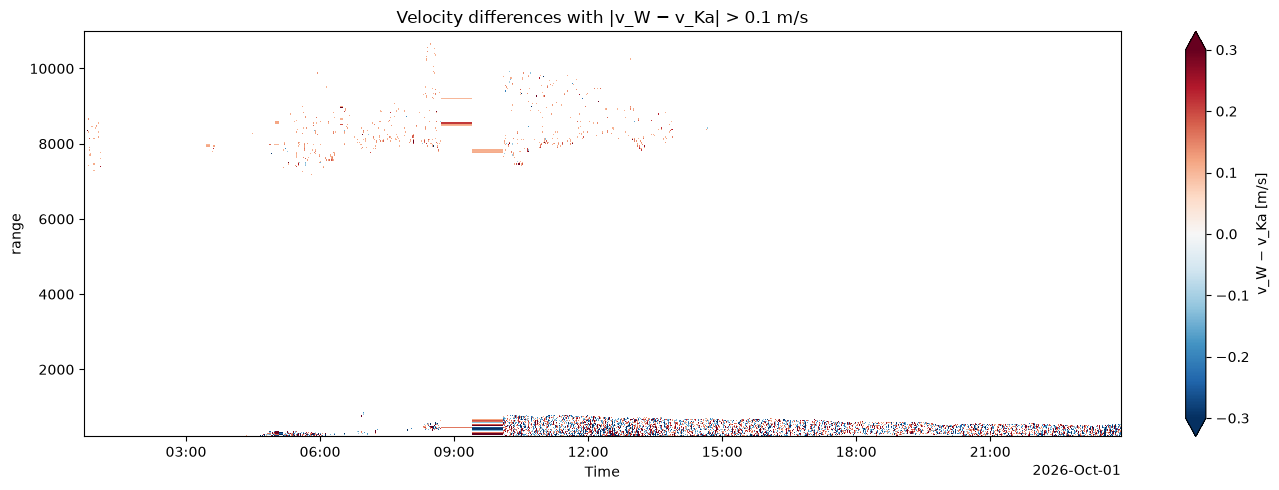

In [35]:
# %% Velocity differences exceeding |dv| > 0.1 m/s
fig, ax = plt.subplots(figsize=(14, 5))
dv_2km.where(np.abs(dv_2km) > 0.1).plot(
    x="Time", y="range", ax=ax, cmap="RdBu_r", vmin=-0.3, vmax=0.3,
    cbar_kwargs={"label": "v_W − v_Ka [m/s]"})
ax.set_title("Velocity differences with |v_W − v_Ka| > 0.1 m/s")
plt.tight_layout(); plt.show()

Fraction retained (common_mask & drizzle_mask): 1.64%
Fraction retained by common_mask alone:         4.53%


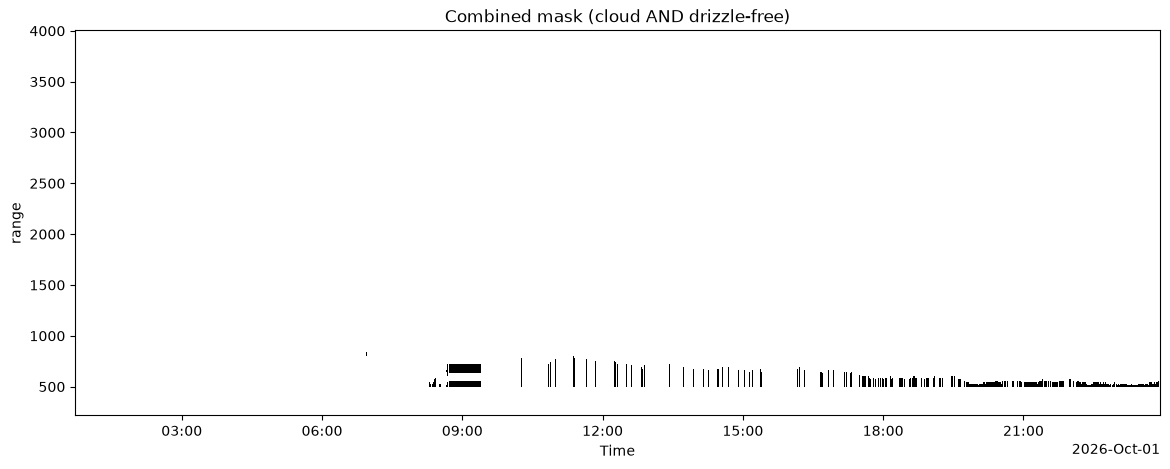

In [36]:
# %% Combine common_mask AND drizzle_mask into one mask
combined_mask = common_mask & drizzle_mask
combined_mask.name = "combined_mask"

combined_mask = combined_mask.where(combined_mask["range"] >= 500, False)
common_mask = common_mask.where(common_mask["range"] >= 500, False)

print(f"Fraction retained (common_mask & drizzle_mask): {float(combined_mask.mean()):.2%}")
print(f"Fraction retained by common_mask alone:         {float(common_mask.mean()):.2%}")

# %% Plot
fig, ax = plt.subplots(figsize=(14, 5))

combined_mask.sel(range=slice(0, 4000)).plot(
    x="Time", y="range", cmap="Greys",
    add_colorbar=False, ax=ax,
)

ax.set_title("Combined mask (cloud AND drizzle-free)")
plt.show()

In [37]:
combined_mask = (
    cloud_mask
    & sig_W & neighbour_mask_W
    & sig_Ka & neighbour_mask_Ka
    & drizzle_mask
)
combined_mask.name = "combined_mask"

dwr = ds["Ze_Ka"] - ds["Ze_W"]        # raw DWR, order doesn't matter here
dwr.name = "DWR"

dwr_2km_masked = dwr_2km.where(combined_mask)  # apply everything in one shot

print(f"Fraction retained: {float(combined_mask.mean()):.2%}")

Fraction retained: 2.91%


## SLICE ALL VALUES UP TO 2KM

In [38]:
dwr_2km = dwr.sel(range=slice(0, 4000))
cloud_mask_2km = cloud_mask.sel(range=slice(0, 4000))
common_mask_2km = common_mask.sel(range=slice(0, 4000))
combined_mask_2km = combined_mask.sel(range=slice(0, 4000))

alpha_w_2km = alpha_w.sel(range=slice(0, 4000))
alpha_ka_2km = alpha_ka.sel(range=slice(0, 4000))

kappa_w_2km = kappa_w.sel(range=slice(0, 4000))
kappa_ka_2km = kappa_ka.sel(range=slice(0, 4000))

alpha_W_2km = alpha_W.sel(range=slice(0, 4000))
alpha_Ka_2km = alpha_Ka.sel(range=slice(0, 4000))

kappa_W_2km = kappa_W.sel(range=slice(0, 4000))
kappa_Ka_2km = kappa_Ka.sel(range=slice(0, 4000))

meanvel_W = ds["MeanVel_W"].sel(range=slice(0, 4000))
meanvel_Ka = ds["MeanVel_Ka"].sel(range=slice(0, 4000))

## SAVE RETRIEVALS

In [39]:
# Cell FINAL — Save retrieval_input.nc

from pathlib import Path
import xarray as xr

ds_retrieval = xr.Dataset(
    {
        # Original radar measurements (useful for diagnostics)
        "Ze_W": ds["Ze_W"],
        "Ze_Ka": ds["Ze_Ka"],

        # Auxiliary data
        "T_cloud": ds["T_cloud"],
        "LWP": ds["LWP"],

        # Retrieval inputs
        "DWR": dwr.rename("DWR"),
        "cloud_mask": cloud_mask.rename("cloud_mask"),
        "combined_mask": combined_mask.rename("combined_mask"),
        "common_mask": common_mask.rename("common_mask"),

        # Gas attenuation
        "alpha_W": alpha_w.rename("alpha_W"),
        "alpha_Ka": alpha_ka.rename("alpha_Ka"),

        # Liquid attenuation coefficients
        "kappa_W": kappa_w.rename("kappa_W"),
        "kappa_Ka": kappa_ka.rename("kappa_Ka"),

        #Mean Doppler Velocity
        "MeanVel_W": ds["MeanVel_W"],
        "MeanVel_Ka": ds["MeanVel_Ka"],
    },
    attrs={
        "description": "Prepared inputs for Zhu et al. (2019) LWC retrieval",
        "date": "20230928",
        "site": "Cabauw",
        "created_by": "03_dwr_and_masking.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)

ds_retrieval.to_netcdf(out_path)

print(f"Saved → {out_path}")
print(ds_retrieval)

Saved → ..\data\processed\20261001_pallas_interpolation\retrieval_input.nc
<xarray.Dataset> Size: 1GB
Dimensions:        (Time: 29682, range: 434)
Coordinates:
  * Time           (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ...
  * range          (range) float64 3kB 223.6 238.5 253.4 ... 1.094e+04 1.097e+04
Data variables: (12/14)
    Ze_W           (Time, range) float64 103MB nan nan nan nan ... nan nan nan
    Ze_Ka          (Time, range) float64 103MB nan nan nan nan ... nan nan nan
    T_cloud        (Time, range) float64 103MB 277.7 277.9 278.1 ... nan nan nan
    LWP            (Time) float32 119kB ...
    DWR            (Time, range) float64 103MB nan nan nan nan ... nan nan nan
    cloud_mask     (Time, range) bool 13MB False False False ... False False
    ...             ...
    alpha_W        (Time, range) float64 103MB 0.65 0.65 0.65 ... 0.65 0.65 0.65
    alpha_Ka       (Time, range) float64 103MB 0.14 0.14 0.14 ... 0.14 0.14 0.14
    kappa_W        (Time, ran

In [40]:
# Cell FINAL 2 KM— Save retrieval_input.nc

from pathlib import Path
import xarray as xr

ds_retrieval_2km = xr.Dataset(
    {
        # Radar measurements
        "Ze_W": ds["Ze_W"].sel(range=slice(0, 4000)),
        "Ze_Ka": ds["Ze_Ka"].sel(range=slice(0, 4000)),

        # Auxiliary data
        "T_cloud": ds["T_cloud"].sel(range=slice(0, 4000)),
        "LWP": ds["LWP"],

        # Retrieval inputs
        "DWR": dwr_2km.rename("DWR"),
        "cloud_mask": cloud_mask_2km.rename("cloud_mask"),
        "combined_mask": combined_mask_2km.rename("combined_mask"),
        "common_mask": common_mask_2km.rename("common_mask"),

        # Gas attenuation
        "alpha_W": alpha_w_2km.rename("alpha_W"),
        "alpha_Ka": alpha_ka_2km.rename("alpha_Ka"),

        # Liquid attenuation coefficients
        "kappa_W": kappa_w_2km.rename("kappa_W"),
        "kappa_Ka": kappa_ka_2km.rename("kappa_Ka"),
        #Mean Doppler Velocity
        "MeanVel_W": meanvel_W.rename("MeanVel_W"),
        "MeanVel_Ka": meanvel_Ka.rename("MeanVel_Ka"),
    },
    attrs={
        "description": "Prepared inputs for Zhu et al. (2019) LWC retrieval (0–2 km)",
        "date": "20230928",
        "site": "Cabauw",
        "created_by": "03_dwr_and_masking.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)

ds_retrieval_2km.to_netcdf(out_path)

print(f"Saved → {out_path}")
print(ds_retrieval_2km)

Saved → ..\data\processed\20261001_pallas_interpolation\retrieval_input_4km.nc
<xarray.Dataset> Size: 565MB
Dimensions:        (Time: 29682, range: 229)
Coordinates:
  * Time           (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ...
  * range          (range) float64 2kB 223.6 238.5 253.4 ... 3.952e+03 3.986e+03
Data variables: (12/14)
    Ze_W           (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    Ze_Ka          (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    T_cloud        (Time, range) float64 54MB 277.7 277.9 278.1 ... 270.3 270.1
    LWP            (Time) float32 119kB ...
    DWR            (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    cloud_mask     (Time, range) bool 7MB False False False ... False False
    ...             ...
    alpha_W        (Time, range) float64 54MB 0.65 0.65 0.65 ... 0.65 0.65 0.65
    alpha_Ka       (Time, range) float64 54MB 0.14 0.14 0.14 ... 0.14 0.14 0.14
    kappa_W        (Time, rang

In [41]:
# Cell FINAL 2 KM— Save retrieval_input.nc

from pathlib import Path
import xarray as xr

ds_retrieval_2km_alpha_kappa = xr.Dataset(
    {
        # Radar measurements
        "Ze_W": ds["Ze_W"].sel(range=slice(0, 4000)),
        "Ze_Ka": ds["Ze_Ka"].sel(range=slice(0, 4000)),

        # Auxiliary data
        "T_cloud": ds["T_cloud"].sel(range=slice(0, 4000)),
        "LWP": ds["LWP"],

        # Retrieval inputs
        "DWR": dwr_2km.rename("DWR"),
        "cloud_mask": cloud_mask_2km.rename("cloud_mask"),
        "combined_mask": combined_mask_2km.rename("combined_mask"),
        "common_mask": common_mask_2km.rename("common_mask"),

        # Gas attenuation
        "alpha_W": alpha_W_2km.rename("alpha_W"),
        "alpha_Ka": alpha_Ka_2km.rename("alpha_Ka"),

        # Liquid attenuation coefficients
        "kappa_W": kappa_W_2km.rename("kappa_W"),
        "kappa_Ka": kappa_Ka_2km.rename("kappa_Ka"),
        
        #Mean Doppler Velocity
        "MeanVel_W": meanvel_W.rename("MeanVel_W"),
        "MeanVel_Ka": meanvel_Ka.rename("MeanVel_Ka"),

        
    },
    attrs={
        "description": "Prepared inputs for Zhu et al. (2019) LWC retrieval with alpha and kappa calculated (0–2 km)",
        "date": "20230928",
        "site": "Cabauw",
        "created_by": "03_dwr_and_masking.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)

ds_retrieval_2km_alpha_kappa.to_netcdf(out_path)

print(f"Saved → {out_path}")
print(ds_retrieval_2km_alpha_kappa)

Saved → ..\data\processed\20261001_pallas_interpolation\retrieval_input_4km_alpha_kappa_calculated.nc
<xarray.Dataset> Size: 565MB
Dimensions:        (Time: 29682, range: 229)
Coordinates:
  * Time           (Time) datetime64[ns] 237kB 2026-10-01T00:43:14.052958488 ...
  * range          (range) float64 2kB 223.6 238.5 253.4 ... 3.952e+03 3.986e+03
Data variables: (12/14)
    Ze_W           (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    Ze_Ka          (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    T_cloud        (Time, range) float64 54MB 277.7 277.9 278.1 ... 270.3 270.1
    LWP            (Time) float32 119kB ...
    DWR            (Time, range) float64 54MB nan nan nan nan ... nan nan nan
    cloud_mask     (Time, range) bool 7MB False False False ... False False
    ...             ...
    alpha_W        (Time, range) float64 54MB 0.3576 0.355 ... 0.03936 0.03888
    alpha_Ka       (Time, range) float64 54MB 0.09116 0.09058 ... 0.01792
    kappa_W   

In [42]:
import os
print(os.path.abspath(out_path))

c:\Projects\Masterarbeit\dual_freq_radar_lwc\data\processed\20261001_pallas_interpolation\retrieval_input_4km_alpha_kappa_calculated.nc


In [43]:
from pathlib import Path

out_path = Path("../data/processed/retrieval_input_2km.nc")

print(out_path.exists())

try:
    out_path.unlink()
    print("Deleted successfully.")
except Exception as e:
    print(type(e).__name__, e)

False
FileNotFoundError [WinError 2] Das System kann die angegebene Datei nicht finden: '..\\data\\processed\\retrieval_input_2km.nc'
